# Dataset Inspection — Adult Census Income

This notebook loads and inspects the UCI Adult dataset only. Model training and reweighting experiments are in `03_complete_research_workflow.ipynb`.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path.cwd()
print("Project folder:", DATA_DIR)
for filename in ["adult.data", "adult.test"]:
    if not (DATA_DIR / filename).exists():
        raise FileNotFoundError(
            f"Could not find {filename}. Put this notebook in the same folder as the UCI Adult data files."
        )


Project folder: C:\Users\DELL\OneDrive\Documents\Research Project (Feature Interaction 2)


In [2]:
columns = [
    "age", "workclass", "fnlwgt", "education",
    "education_num", "marital_status", "occupation",
    "relationship", "race", "sex", "capital_gain",
    "capital_loss", "hours_per_week", "native_country",
    "income"
]

train_df = pd.read_csv(
    DATA_DIR / "adult.data",
    names=columns,
    skipinitialspace=True,
    na_values="?",
    skip_blank_lines=True
)

test_df = pd.read_csv(
    DATA_DIR / "adult.test",
    names=columns,
    skipinitialspace=True,
    na_values="?",
    comment="|",
    skip_blank_lines=True
)

# Clean whitespace and standardize target labels.
for data in [train_df, test_df]:
    for col in data.select_dtypes(include="object").columns:
        data[col] = data[col].str.strip()

    data["income"] = data["income"].str.rstrip(".")

print("Training dataset shape:", train_df.shape)
print("Test dataset shape:", test_df.shape)

display(train_df.head())
display(test_df.head())

Training dataset shape: (32561, 15)
Test dataset shape: (16281, 15)


C:\Users\DELL\AppData\Local\Temp\ipykernel_12060\3675719386.py:28: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in data.select_dtypes(include="object").columns:
C:\Users\DELL\AppData\Local\Temp\ipykernel_12060\3675719386.py:28: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guid

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,NaN,103497,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States,<=50K


Training data information:
<class 'pandas.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             32561 non-null  int64
 1   workclass       30725 non-null  str  
 2   fnlwgt          32561 non-null  int64
 3   education       32561 non-null  str  
 4   education_num   32561 non-null  int64
 5   marital_status  32561 non-null  str  
 6   occupation      30718 non-null  str  
 7   relationship    32561 non-null  str  
 8   race            32561 non-null  str  
 9   sex             32561 non-null  str  
 10  capital_gain    32561 non-null  int64
 11  capital_loss    32561 non-null  int64
 12  hours_per_week  32561 non-null  int64
 13  native_country  31978 non-null  str  
 14  income          32561 non-null  str  
dtypes: int64(6), str(9)
memory usage: 3.7 MB

Missing values in training data:


,missing_values
age,0
workclass,1836
fnlwgt,0
education,0
education_num,0
marital_status,0
occupation,1843
relationship,0
race,0
sex,0



Question-mark values should now be missing values.

Training income counts:


income
<=50K    24720
>50K      7841
Name: count, dtype: int64


Test income counts:


...


Numerical columns:


['age',
 'fnlwgt',
 'education_num',
 'capital_gain',
 'capital_loss',
 'hours_per_week']


Categorical columns:


C:\Users\DELL\AppData\Local\Temp\ipykernel_12060\1187254190.py:24: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(train_df.select_dtypes(include="object").columns.tolist())


['workclass',
 'education',
 'marital_status',
 'occupation',
 'relationship',
 'race',
 'sex',
 'native_country',
 'income']

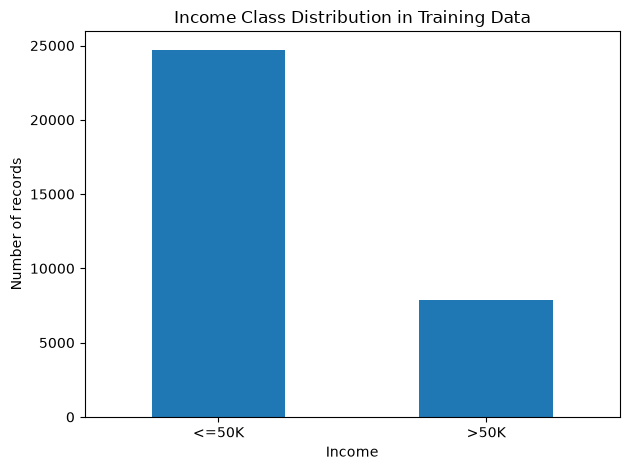

In [3]:
print("Training data information:")
train_df.info()

print("\nMissing values in training data:")
display(train_df.isna().sum().to_frame("missing_values"))

print("\nQuestion-mark values should now be missing values.")
print("\nTraining income counts:")
display(train_df["income"].value_counts())

print("\nTest income counts:")
display(test_df["income"].value_counts())

print("\nTraining income proportions:")
display(train_df["income"].value_counts(normalize=True).round(4))

print("\nTest income proportions:")
display(test_df["income"].value_counts(normalize=True).round(4))

print("\nNumerical columns:")
display(train_df.select_dtypes(include=np.number).columns.tolist())

print("\nCategorical columns:")
display(train_df.select_dtypes(include="object").columns.tolist())

train_df["income"].value_counts().plot(
    kind="bar",
    title="Income Class Distribution in Training Data",
    xlabel="Income",
    ylabel="Number of records"
)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()